# Results tour

This notebook only **displays** results. The source of truth is the scripts in [`analysis/`](../analysis), run by `python run_pipeline.py`, which write `results/`.

Run the pipeline first if `results/` is empty.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

R = Path('..') / 'results'
M = json.loads((R / 'metrics.json').read_text())
show = lambda q: display(Markdown((R / f'{q}.md').read_text(encoding='utf-8')))
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## Q00 · Is the export fit for analysis?

In [2]:
show('q00')

## Q00 · Data profile

> **Question:** Before we answer business questions: what in this export is unusable or misleading as-is?

| Table | Rows |
|---|---|
| customer_accounts | 16,929 |
| subscription_events | 46,370 |
| support_tickets | 8,908 |
| product_usage_monthly | 121,910 |

- **550 exact duplicate rows** in `subscription_events` (same `event_id`): count events with `DISTINCT`.
- **7 events dated 1970-01-01**: placeholder timestamps, which must be excluded from any time-based logic.
- **52 account_ids appear in events but not in `customer_accounts`**: they were deleted from the CRM, but their billing history remains.
- **32 internal QA accounts** (`billing_email_domain = qa-internal.example`, MRR = $1) produce **110 cancellations**, because they exercise the cancel flow.
- **15 spellings of 5 plans** ('Enterprise', 'Enterprise ', 'Free', 'Free ', 'Growth', 'Growth ', 'Starter', 'Starter ', 'Trial', 'Trial ', 'enterprise', 'free', 'growth', 'starter', 'trial'): normalise with `strip().title()`.
- **MRR is ~100× too large in 2024-03, 2024-04, 2024-05** (median MRR per event: 38,838 vs 549 in other months, 757 rows, all `source_system = billing_v1`). The legacy system stored cents. Any account whose *latest* event falls in that window carries the inflated value forward.
- **Sessions per active user fall 60% in 2025-08**, while active users stay flat. That looks like a product-analytics outage, so avoid session-based trends across that month.
- Nulls in `customer_accounts`: industry 1,170, company_size 630, last_nps_score 13,633, cancellation_reason 15,960
- Dropping accounts with missing industry or company_size would silently remove **1,761 of 16,929 accounts**, along with every event, ticket and usage row attached to them.
- **Point-in-time warning:** `customer_accounts` reflects the CRM on the export date (2026-10-31). These fields are *current* values, not history: `account_status`, `current_plan`, `current_seats`, `current_mrr`, `cancellation_reason`, `last_cancellation_date`, `last_login_date`, `last_nps_score`. Don't use them as features for any period before the export.


## Q01 · The quick answer

In [3]:
show('q01')

## Q01 · Q1 2026 churn rate

> **Question:** Show me the churn rate for Q1 2026.

Running [`sql/q1_churn_rate.sql`](../sql/q1_churn_rate.sql) against `data/saas_churn.sqlite`:

**Q1 2026 churn rate = 6.3%** (262 accounts with a cancellation / 4,132 paying accounts on 2026-01-01).

The query runs and returns one clean number. Every definition choice inside it is examined in Q02.


## Q02 · One number, many definitions

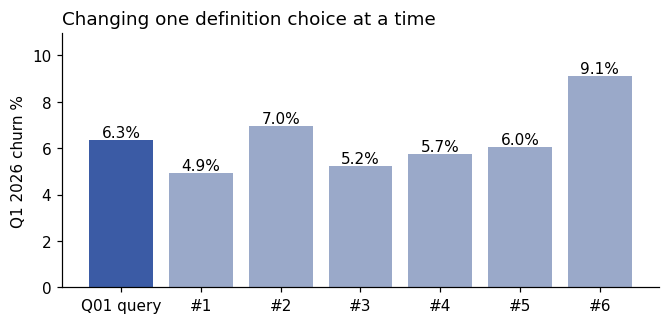

## Q02 · Churn definition sensitivity

> **Question:** Which business decisions are hidden inside the Q1 churn number, and how much does each one move it?

Each row changes **one** choice, starting from the straightforward query in Q01 (its choice is the first option in every row).

| # | Question | Q01 choice | Alternative |
|---|---|---|---|
| 1 | Does a refund count as lost? | Yes **6.3%** | No **4.9%** |
| 2 | Which date do we attribute the cancellation to? | End of term (effective) **6.3%** | Request date **6.9%** |
| 3 | If they reactivate the same day, did they churn? | Yes **6.3%** | No **5.3%** |
| 4 | If they reactivate within 90 days, did they churn? | Yes **6.3%** | No **5.7%** |
| 5 | Which denominator do we use? | Start of period **6.3%** | Average over period **6.0%** |
| 6 | Do expired trials or downgrades to Free count? | Exclude **6.3%** | Include **9.1%** |

- Single-choice range: **4.9% to 9.1%**. Six defensible answers, and the quick query picked one without saying so.
- Combining request date, no same-day reactivations, no reactivations within 90 days and an average denominator gives **5.0%**.
- Removing the internal QA accounts (see Q00) moves the Q01 number to **6.2%**.


In [4]:
q2 = M['q02']
labels = ['Q01 query'] + [f'#{i}' for i in range(1, 7)]
vals = [q2['base_pct']] + list(q2['variants_pct'].values())
fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.bar(labels, vals, color=['#3B5BA5'] + ['#9AA9C9'] * 6)
ax.bar_label(bars, fmt='%.1f%%'); ax.set_ylabel('Q1 2026 churn %'); ax.set_ylim(0, max(vals) * 1.2)
ax.set_title('Changing one definition choice at a time', loc='left'); plt.show()
show('q02')

## Q03 · What distinguishes churned accounts?

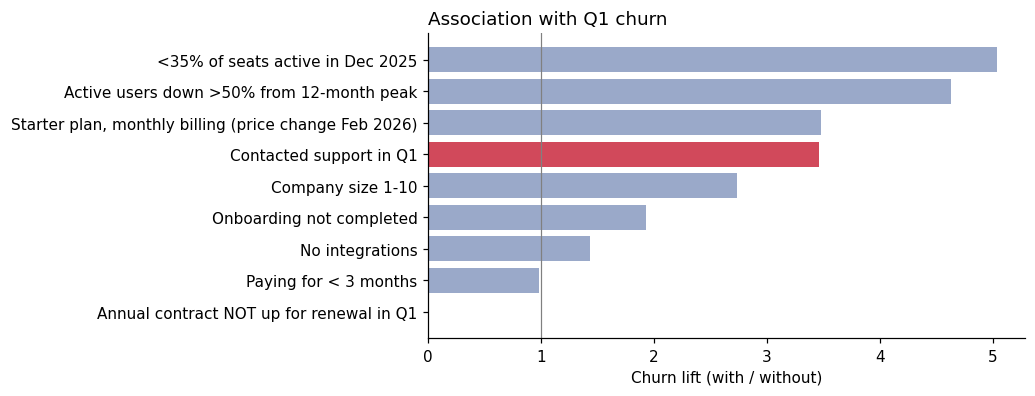

## Q03 · Churn drivers (EDA)

> **Question:** What drove churn in Q1 2026? Compare churned vs retained accounts on every signal and rank the drivers.

Cohort: **4,092 paying accounts on 2026-01-01** (internal and CRM-deleted accounts removed). Label: voluntary churn decision in Q1 (a cancel request or a downgrade to Free), **5.3%**.

| Signal | Accounts | Churn with | Churn without | Lift |
|---|---|---|---|---|
| <35% of seats active in Dec 2025 | 423 | 18.9% | 3.8% | **5.0×** |
| Active users down >50% from 12-month peak | 337 | 19.0% | 4.1% | **4.6×** |
| Starter plan, monthly billing (price change Feb 2026) | 1,356 | 10.2% | 2.9% | **3.5×** |
| Contacted support in Q1 | 805 | 12.4% | 3.6% | **3.5×** |
| Company size 1-10 | 1,067 | 10.0% | 3.7% | **2.7×** |
| Onboarding not completed | 1,062 | 8.3% | 4.3% | **1.9×** |
| No integrations | 1,349 | 6.7% | 4.7% | **1.4×** |
| Paying for < 3 months | 555 | 5.2% | 5.3% | **1.0×** |
| Annual contract NOT up for renewal in Q1 | 1,103 | 0.1% | 7.3% | **0.0×** |

Cancel requests per month from this cohort (the Starter monthly price rose on 2026-02-01):

| Month | Other | Starter monthly |
|---|---|---|
| 2025-10 | 1 | 4 |
| 2025-11 | 0 | 1 |
| 2025-12 | 5 | 13 |
| 2026-01 | 21 | 20 |
| 2026-02 | 21 | 40 |
| 2026-03 | 26 | 59 |

**Small samples:** 79 industry × country segments have only 10–29 accounts. The highest churn rate among them, **Media / BR**, is 2 of 10 = 20% (vs 5.3% overall). Fisher exact p = 0.10, and with 79 segments compared, a gap this size is expected by chance. **Not a finding.**
Government is the smallest industry: n = 20, 1 churned.

*Lift is association, not cause. Q04 tests the top signal.*


In [5]:
lifts = M['q03']['lifts']
fig, ax = plt.subplots(figsize=(7, 3.6))
names, vals = list(lifts)[::-1], list(lifts.values())[::-1]
ax.barh(names, vals, color=['#D1495B' if 'support' in n else '#9AA9C9' for n in names])
ax.axvline(1, color='grey', lw=0.8); ax.set_xlabel('Churn lift (with / without)')
ax.set_title('Association with Q1 churn', loc='left'); plt.show()
show('q03')

## Q04 · Does contacting support cause churn?

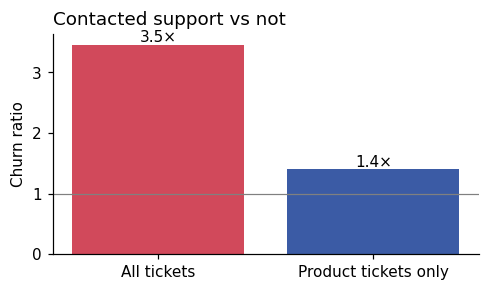

## Q04 · Support contact and churn

> **Question:** Customers who contacted support churn far more often. Is support causing churn, and would investing in support quality reduce it?

**1. The association** (the headline an automated analysis reports):

- Contacted support in Q1: churn **12.4%** (n = 805)
- Did not contact support: churn **3.6%**
- **3.5× more likely to churn**

**2. When and why did churners contact support?**

- **70%** of churners' Q1 tickets were filed **0–14 days before their cancel request**.
- Those tickets are mostly about leaving: `cancellation` 35%, `data_export` 19%, `billing` 19%.
- So the sequence is: *decide to leave → ask how to cancel or export data → cancel*. The ticket is a **symptom** of the decision, not its cause.

**3. Counting product tickets only** (how-to, bug, integration, feature request):

- Churn 7.0% vs 5.0% → **1.4×**. Most of the association disappears.

**4. Is support quality worse for churners?**

- CSAT: churners 2.8 vs retained 4.0. That *looks* like bad support.
- Median first response: churners 4.5 h vs retained 5.2 h. Churners were **not served slower**; people on their way out rate the interaction lower.

**Conclusion:** the evidence points to reverse causality. Spending on support quality to reduce churn would act too late: by the time the ticket arrives, the decision has been made. Use a cancellation, billing or export ticket as an **early-warning trigger** for a retention conversation instead, and look upstream (Q03: usage, champion loss, early tenure, the price change) for causes.


In [6]:
q4 = M['q04']
fig, ax = plt.subplots(figsize=(5, 2.6))
b = ax.bar(['All tickets', 'Product tickets only'], [q4['ratio_all_tickets'], q4['ratio_product_tickets_only']],
           color=['#D1495B', '#3B5BA5'])
ax.bar_label(b, fmt='%.1f×'); ax.axhline(1, color='grey', lw=0.8)
ax.set_ylabel('Churn ratio'); ax.set_title('Contacted support vs not', loc='left'); plt.show()
show('q04')

## Q05 · Three ways to build a churn model

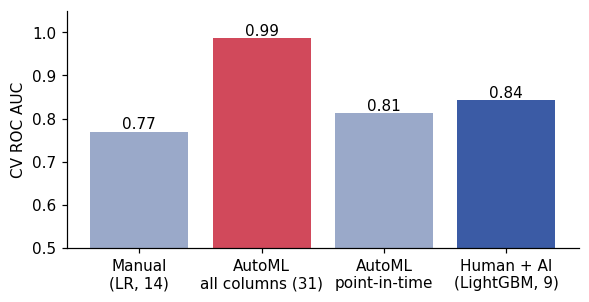

## Q05 · Churn prediction: three builds

> **Question:** Build a model that scores every paying account by its risk of churning in Q1 2026.

Cohort: 4,092 paying accounts on 2026-01-01; label = voluntary churn decision in Q1 2026 (5.3% positive). All scores are 5-fold stratified cross-validated ROC AUC.

| Build | Model | Features | AUC |
|---|---|---|---|
| A · Manual | Logistic regression | 14 | **0.77** ± 0.03 |
| B · AutoML, all columns | Stack (LR + RF + GBM) | 31 | **0.99** ± 0.01 |
| C · Human + AI | LightGBM | 9 | **0.84** ± 0.01 |

**Leakage audit for B.** Top features by permutation importance: `days_since_last_cancellation`, `days_since_last_login`, `account_status`, `min_last3`. Most are CRM fields that hold their value on the **export date (2026-10-31)**, after the Q1 label window (see Q00). They encode the outcome: a customer who left in Q1 has a recent cancellation date and an old last login. That model cannot exist on 2026-01-01.
- Same AutoML stack with the export-time columns removed: **0.81** ± 0.01.

**Build C** uses only point-in-time features, plus one piece of domain context: annual contracts can only be cancelled at renewal (`renewal_due_q1`). It is the only one of the three that is both honest and better than the baseline.


In [7]:
q5 = M['q05']
fig, ax = plt.subplots(figsize=(6, 2.8))
names = ['Manual\n(LR, 14)', 'AutoML\nall columns (31)', 'AutoML\npoint-in-time', 'Human + AI\n(LightGBM, 9)']
vals = [q5['auc_manual'], q5['auc_automl_all_columns'], q5['auc_automl_point_in_time'], q5['auc_human_ai']]
b = ax.bar(names, vals, color=['#9AA9C9', '#D1495B', '#9AA9C9', '#3B5BA5'])
ax.bar_label(b, fmt='%.2f'); ax.set_ylim(0.5, 1.05); ax.set_ylabel('CV ROC AUC'); plt.show()
show('q05')

## Q06 · Golden set

In [8]:
show('q06')

## Q06 · Golden set

> **Question:** Which questions with known answers should any automated analysis of this data get right?

Saved to [`results/golden_set.csv`](golden_set.csv). Ask an agent these questions and compare its answers before trusting it with open-ended ones.

| # | Question | Answer |
|---|---|---|
| 1 | How many rows does subscription_events have (raw)? | 46,370 |
| 2 | How many exact duplicate rows are in subscription_events? | 550 |
| 3 | How many accounts are in customer_accounts? | 16,929 |
| 4 | How many internal QA accounts exist? | 32 |
| 5 | How many account_ids appear in events but not in customer_accounts? | 52 |
| 6 | How many accounts were paying (MRR > 0) at 2026-01-01 00:00, raw events? | 4,132 |
| 7 | Same, excluding internal and CRM-deleted accounts? | 4,092 |
| 8 | Q1 2026 churn % from sql/q1_churn_rate.sql? | 6.3 |
| 9 | Same, excluding internal accounts? | 6.2 |
| 10 | Cancel requests in Q1 2026 (deduplicated, excluding internal)? | 223 |
| 11 | Refund events in Q1 2026? | 59 |
| 12 | Accounts with a same-day cancellation + reactivation in Q1 2026 (excluding internal)? | 40 |
| 13 | Accounts that received the 2026-02-01 price change? | 1,426 |
| 14 | Total MRR on 2026-01-01 of the clean paying cohort (USD, rounded)? | 8,684,685 |
| 15 | Support tickets created in Q1 2026? | 1,035 |
| 16 | Most common ticket category in Q1 2026? | how_to |
| 17 | Distinct spellings in subscription_events.plan? | 15 |
| 18 | Events with a 1970-01-01 timestamp? | 7 |
| 19 | Month in which product analytics undercounted sessions? | 2025-08 |
| 20 | Voluntary Q1 2026 churn rate of the clean cohort (%)? | 5.3 |
